In [1]:
# Setup

%load_ext autoreload
%autoreload 2

import sys
import json
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.generation import load_checkpoint, generate

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", device)

Project root: C:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention
Device: cpu


In [2]:
# Checkpoints

checkpoint_path = CHECKPOINT_DIR / "mini_gpt_best.pt"

model, tokenizer, checkpoint = load_checkpoint(
    path=checkpoint_path,
    device=device
)

model.eval()

print("Model loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)
print("Model configuration:", model.config)
print("Best iteration:", checkpoint["step"])
print("Best validation loss:", checkpoint["val_loss"])

Model loaded successfully!
Vocabulary size: 65
Model configuration: GPTConfig(vocab_size=65, block_size=64, n_embd=128, n_heads=4, n_layers=2, ffn_dim=512, dropout=0.1)
Best iteration: 2000
Best validation loss: 1.8499236941337585


In [3]:
# Prompting

prompts = [
    "ROMEO:\n",
    "JULIET:"
]

for prompt in prompts:
    prompt_ids = tokenizer.encode(prompt)

    print("Prompt:", repr(prompt))
    print("Token IDs:", prompt_ids)
    print()

Prompt: 'ROMEO:\n'
Token IDs: [30, 27, 25, 17, 27, 10, 0]

Prompt: 'JULIET:'
Token IDs: [22, 33, 24, 21, 17, 32, 10]



In [4]:
# Text Generation

prompt = "ROMEO:\n"

prompt_ids = tokenizer.encode(prompt)

idx = torch.tensor(
    prompt_ids,
    dtype=torch.long,
    device=device
).unsqueeze(0)

torch.manual_seed(42)

generated_ids = generate(
    model=model,
    idx=idx,
    max_new_tokens=500,
    block_size=model.config.block_size,
    temperature=0.8,
    top_k=20
)

generated_text = tokenizer.decode(generated_ids[0].tolist())

print(generated_text)

ROMEO:
You lord shall, in we my chard's to fat,
And cour boyer and cere and the dreath be that you,
How soul, that is not this can my chearth, not lord,
The the fall for not I
haven if the shall mine his, but me hose,
For how and woman not the can
They home do know and were counsiton,
I may I comes and abreath that shall frince,
How can the forfe, thou sould that bise?

RICK:
Were the was to wild dea scalin, aft and the hand
And that night polime wither here not you:
Be in me not in they such wereen fo


In [5]:
# Experiments

temperatures = [0.5, 0.8, 1.0, 1.2]

for temperature in temperatures:

    torch.manual_seed(42)

    generated_ids = generate(
        model=model,
        idx=idx,
        max_new_tokens=250,
        block_size=model.config.block_size,
        temperature=temperature,
        top_k=20
    )

    generated_text = tokenizer.decode(
        generated_ids[0].tolist()
    )

    print("=" * 70)
    print("Temperature:", temperature)
    print(generated_text)
    print()

Temperature: 0.5
ROMEO:
My thou fair that the such crown, that not the prove the do courself,
The rest a we man the gracess, be the hound and with me seed
That not my have the be and for the preath,
Which but the care as and sould should the canst
What not the can a seat me

Temperature: 0.8
ROMEO:
You lord shall, in we my chard's to fat,
And cour boyer and cere and the dreath be that you,
How soul, that is not this can my chearth, not lord,
The the fall for not I
haven if the shall mine his, but me hose,
For how and woman not the can
They home

Temperature: 1.0
ROMEO:
You look shad may day drect sun.

SAENNIO:
Be no thou fear heed lam: the dreath, we man's pland hear
To the is up.

AUANUS:
Whereeptial not lal not, a would preng not prevern,
They but not night a, but me be dish him.

FORD:
And not thouu day reat my

Temperature: 1.2
ROMEO:
Yiu look shad may: whonger: sun.

SAEWLIO:
Be nek, you lad heed lam: the dreach be to our planly soid,
For theiu
neveith famenter: that noble lence,

In [6]:
# Top-k sampling

top_k_values = [None, 5, 20]

for top_k in top_k_values:

    torch.manual_seed(42)

    generated_ids = generate(
        model=model,
        idx=idx,
        max_new_tokens=250,
        block_size=model.config.block_size,
        temperature=0.8,
        top_k=top_k
    )

    generated_text = tokenizer.decode(
        generated_ids[0].tolist()
    )

    print("=" * 70)
    print("Top-k:", top_k)
    print(generated_text)
    print()

Top-k: None
ROMEO:
You lord shall, in we my chard's to fatness.

GLEO:
Merear here lam: the dreath, we man, thegely soul, that is up.

AUCEN

COMIO:
For hing the hown, a would preng not breaten, for the bethen hastannow shell should;
Why can which not the under eyet me

Top-k: 5
ROMEO:
This the shall, and more hear hear to they count the siner hee that to to he crain that soun the soul,
What to my canst the diself that the cale the hown take how see one.

KING RICHARD II:
What shall soul shall think of hand the hand heard
The whome

Top-k: 20
ROMEO:
You lord shall, in we my chard's to fat,
And cour boyer and cere and the dreath be that you,
How soul, that is not this can my chearth, not lord,
The the fall for not I
haven if the shall mine his, but me hose,
For how and woman not the can
They home



Attention input:
'First Citizen:\nBefore we'

Input shape: torch.Size([1, 24])
Number of Transformer Layers: 2
Layer 1: torch.Size([1, 4, 24, 24])
Layer 2: torch.Size([1, 4, 24, 24])


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19888\1814883865.py:94: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_19888\1814883865.py:96: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  plt.savefig(
c:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


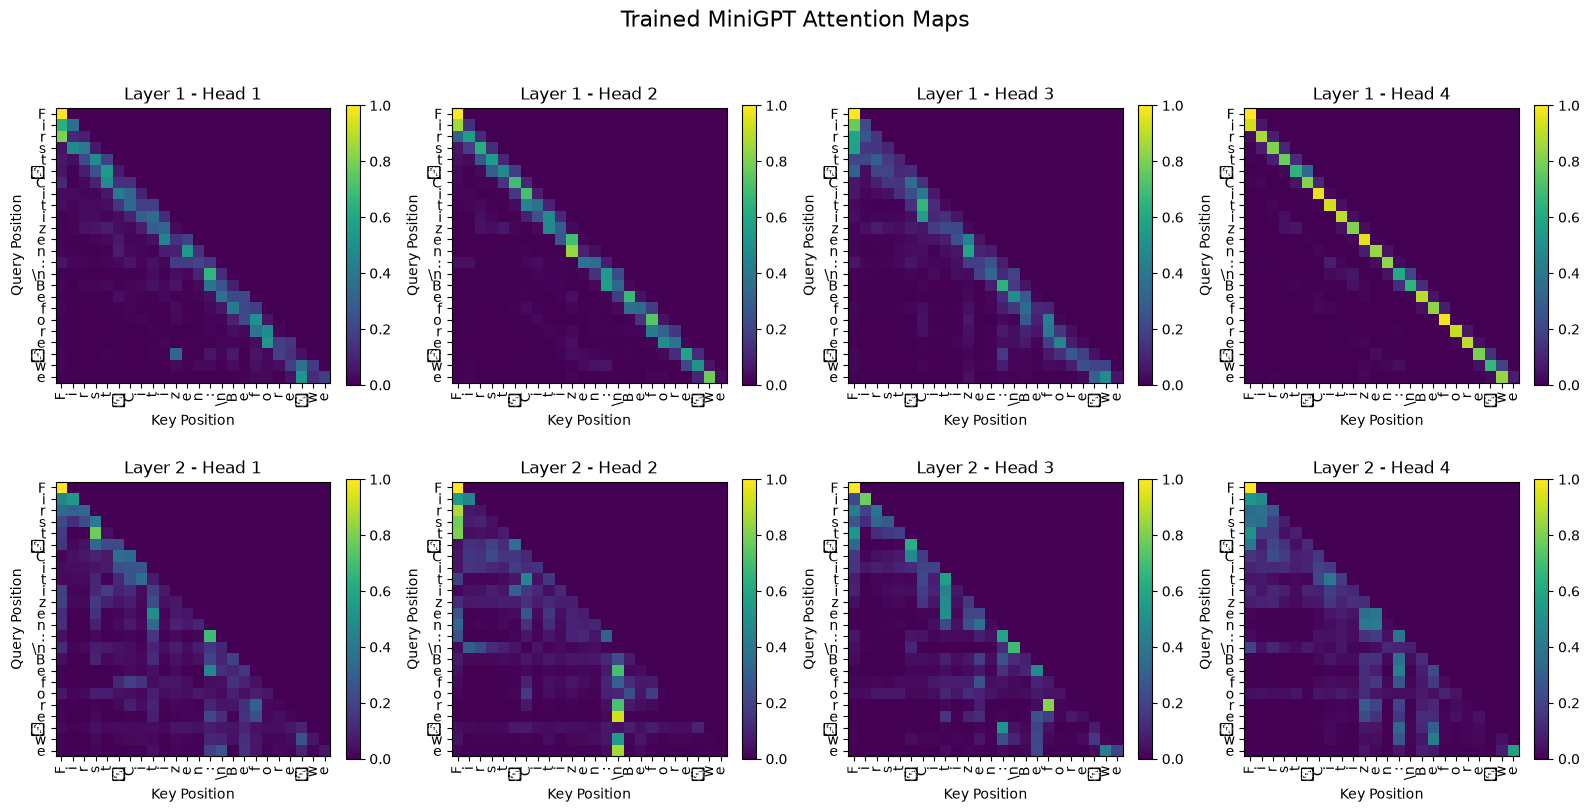

,F,i,r,s,t,␠,C,i,t,i,...,\n,B,e,f,o,r,e,␠,w,e
F,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
i,0.636477,0.363523,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
r,0.801094,0.112942,0.085963,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
s,0.048963,0.478804,0.405814,0.066420,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t,0.066991,0.037741,0.219100,0.482762,0.193405,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
␠,0.053419,0.011019,0.077147,0.255324,0.535838,0.067253,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
C,0.115464,0.007730,0.026282,0.094731,0.485156,0.136097,0.134541,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
i,0.029160,0.030065,0.014219,0.015813,0.062531,0.417662,0.329341,0.101210,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t,0.032191,0.017846,0.030175,0.026268,0.033090,0.155868,0.328662,0.187100,0.188799,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
i,0.007283,0.012882,0.031066,0.028541,0.013855,0.033510,0.092621,0.300866,0.349142,0.130235,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [7]:
# Visualize attention

with open(DATA_DIR / "tinyshakespeare.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

attention_text = raw_text[:24]

attention_ids = tokenizer.encode(attention_text)

idx_attention = torch.tensor(
    attention_ids,
    dtype=torch.long,
    device=device
).unsqueeze(0)

print("Attention input:")
print(repr(attention_text))

print("\nInput shape:", idx_attention.shape)

model.eval()

with torch.no_grad():
    logits, loss, attention_maps = model(
        idx_attention,
        return_attention=True
    )

print("Number of Transformer Layers:", len(attention_maps))

for layer_idx, weights in enumerate(attention_maps):

    print(
        f"Layer {layer_idx + 1}:",
        weights.shape
    )


n_layers = len(attention_maps)
n_heads = attention_maps[0].shape[1]

token_labels = [
    "␠" if char == " " else
    "\\n" if char == "\n" else
    char
    for char in attention_text
]

fig, axes = plt.subplots(
    n_layers,
    n_heads,
    figsize=(4 * n_heads, 4 * n_layers),
    squeeze=False
)

for layer_idx in range(n_layers):

    for head_idx in range(n_heads):

        attention = attention_maps[layer_idx][
            0, head_idx
        ].detach().cpu().numpy()

        ax = axes[layer_idx, head_idx]

        im = ax.imshow(
            attention,
            cmap="viridis",
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f"Layer {layer_idx + 1} - Head {head_idx + 1}"
        )

        ax.set_xlabel("Key Position")
        ax.set_ylabel("Query Position")

        ax.set_xticks(range(len(token_labels)))
        ax.set_xticklabels(token_labels, rotation=90)

        ax.set_yticks(range(len(token_labels)))
        ax.set_yticklabels(token_labels)

        fig.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle(
    "Trained MiniGPT Attention Maps",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "trained_attention_maps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save

attention_df = pd.DataFrame(
    attention_maps[0][0, 0].detach().cpu().numpy(),
    index=token_labels,
    columns=token_labels
)

display(attention_df)

attention_df.to_csv(
    RESULTS_DIR / "attention_layer1_head1.csv"
)


In [9]:
bigram_metrics = pd.read_csv(
    RESULTS_DIR / "bigram_baseline_metrics.csv"
)

mini_gpt_metrics = pd.read_csv(
    RESULTS_DIR / "mini_gpt_metrics.csv"
)

comparison_df = pd.concat(
    [bigram_metrics, mini_gpt_metrics],
    ignore_index=True
)

display(comparison_df)

,Model,Parameters,Test Loss,Test Perplexity,Best Iteration,Best Validation Loss
0,Bigram,4225,2.498061,12.158892,NaN,NaN
1,MiniGPT,420929,1.899879,6.685089,2000.0,1.849924


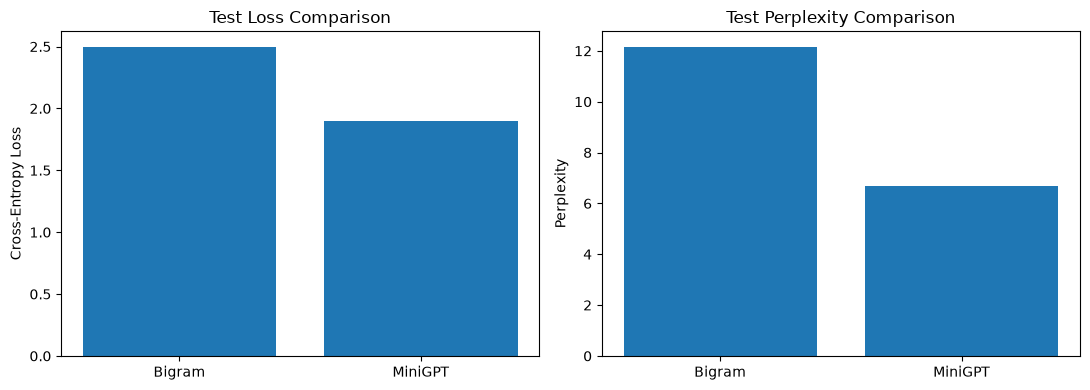

In [10]:
# Model Comparison

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Test Loss
axes[0].bar(
    comparison_df["Model"],
    comparison_df["Test Loss"]
)

axes[0].set_title("Test Loss Comparison")
axes[0].set_ylabel("Cross-Entropy Loss")

# Test Perplexity
axes[1].bar(
    comparison_df["Model"],
    comparison_df["Test Perplexity"]
)

axes[1].set_title("Test Perplexity Comparison")
axes[1].set_ylabel("Perplexity")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "bigram_vs_mini_gpt.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

comparison_df.to_csv(
    RESULTS_DIR / "bigram_vs_mini_gpt.csv",
    index=False
)